In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../1-dataset/credit_risk_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [35]:
print(X.isnull().sum())

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [36]:
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].median())
print(df.isnull().sum())

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [20]:
# Check target variable distribution

print(df["loan_status"].value_counts())

print("\nTarget Variable Percentage:")
print(df["loan_status"].value_counts(normalize=True) * 100)

loan_status
0    25473
1     7108
Name: count, dtype: int64

Target Variable Percentage:
loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64


In [21]:
# Separate Independent and Dependent Variables

X = df.drop("loan_status", axis=1)

y = df["loan_status"]

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (32581, 11)
Y Shape: (32581,)


In [22]:
print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (Y):")
print(y.name)

Independent Variables (X):
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dependent Variable (Y):
loan_status


In [24]:
# Identify numerical and categorical columns

numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

categorical_cols = X.select_dtypes(include=["object", "category"]).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())

print("\nTotal Numerical Columns:", len(numerical_cols))
print("Total Categorical Columns:", len(categorical_cols))

Numerical Columns:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical Columns:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Total Numerical Columns: 7
Total Categorical Columns: 4


/var/folders/zd/xf3dq2z94qq0ctxrz1lgldj80000gn/T/ipykernel_50633/2813046468.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object", "category"]).columns


In [25]:
# Check unique categories

for col in categorical_cols:
    print("\n", col)
    print(df[col].unique())


 person_home_ownership
<ArrowStringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str

 loan_intent
<ArrowStringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str

 loan_grade
<ArrowStringArray>
['D', 'B', 'C', 'A', 'E', 'F', 'G']
Length: 7, dtype: str

 cb_person_default_on_file
<ArrowStringArray>
['Y', 'N']
Length: 2, dtype: str


In [26]:
# Create a copy of X

X_encoded = X.copy()

# One-Hot Encoding

X_encoded = pd.get_dummies(
    X_encoded,
    columns=[
        "person_home_ownership",
        "loan_intent",
        "cb_person_default_on_file"
    ],
    dtype=int,
    drop_first=True
)

# Ordinal Encoding for Loan Grade

grade_mapping = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4,
    "F": 5,
    "G": 6
}

X_encoded["loan_grade"] = X_encoded["loan_grade"].map(grade_mapping)

print("Encoding Completed!")
print("New X Shape:", X_encoded.shape)

X_encoded.head()

Encoding Completed!
New X Shape: (32581, 17)


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,cb_person_default_on_file_Y
0,22,59000,123.0,3,35000,16.02,0.59,3,0,0,1,0,0,0,1,0,1
1,21,9600,5.0,1,1000,11.14,0.10,2,0,1,0,1,0,0,0,0,0
2,25,9600,1.0,2,5500,12.87,0.57,3,0,0,0,0,0,1,0,0,0
3,23,65500,4.0,2,35000,15.23,0.53,2,0,0,1,0,0,1,0,0,0
4,24,54400,8.0,2,35000,14.27,0.55,4,0,0,1,0,0,1,0,0,1


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_encoded,y,test_size=0.20,random_state=42,stratify=y)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (26064, 17)
Testing Data Shape: (6517, 17)
Training Target Shape: (26064,)
Testing Target Shape: (6517,)


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling Completed!")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

Scaling Completed!
X_train_scaled: (26064, 17)
X_test_scaled: (6517, 17)


In [32]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [37]:
y_pred = lr_model.predict(X_test_scaled)

print("Prediction Completed!")
print(y_pred[:10])

Prediction Completed!
[0 0 0 0 0 0 0 0 0 1]


In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.8565290777965322
Model Accuracy (%): 85.65290777965322


In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4849  246]
 [ 689  733]]


In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91      5095
           1       0.75      0.52      0.61      1422

    accuracy                           0.86      6517
   macro avg       0.81      0.73      0.76      6517
weighted avg       0.85      0.86      0.85      6517



In [41]:
from sklearn.linear_model import LogisticRegression

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_balanced.fit(X_train_scaled, y_train)

print("Balanced Logistic Regression Model Trained Successfully!")

Balanced Logistic Regression Model Trained Successfully!


In [42]:
y_pred_balanced = lr_balanced.predict(X_test_scaled)

print("Balanced Model Prediction Completed!")
print(y_pred_balanced[:10])

Balanced Model Prediction Completed!
[0 0 0 0 0 0 0 0 0 1]


In [43]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Balanced Model Accuracy:")
print(accuracy_score(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Model Accuracy:
0.7926960257787325

Confusion Matrix:
[[4052 1043]
 [ 308 1114]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      5095
           1       0.52      0.78      0.62      1422

    accuracy                           0.79      6517
   macro avg       0.72      0.79      0.74      6517
weighted avg       0.84      0.79      0.81      6517



In [44]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [45]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.8953506214515882

Confusion Matrix:
[[4730  365]
 [ 317 1105]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      5095
           1       0.75      0.78      0.76      1422

    accuracy                           0.90      6517
   macro avg       0.84      0.85      0.85      6517
weighted avg       0.90      0.90      0.90      6517



In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Model Training
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

# Step 2: Prediction
y_pred_rf = rf_model.predict(X_test)

print("\nRandom Forest Accuracy:")
print(accuracy_score(y_test, y_pred_rf))

# Step 3: Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Step 4: Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Model Trained Successfully!

Random Forest Accuracy:
0.9274205922970692

Confusion Matrix:
[[4982  113]
 [ 360 1062]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      5095
           1       0.90      0.75      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.92      0.86      0.89      6517
weighted avg       0.93      0.93      0.92      6517



In [47]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                        Feature  Importance
6           loan_percent_income    0.205333
1                 person_income    0.165719
3                    loan_grade    0.136690
5                 loan_int_rate    0.116668
4                     loan_amnt    0.079830
10   person_home_ownership_RENT    0.055186
2             person_emp_length    0.053782
0                    person_age    0.048859
7    cb_person_cred_hist_length    0.038651
9     person_home_ownership_OWN    0.016929
12  loan_intent_HOMEIMPROVEMENT    0.016569
15          loan_intent_VENTURE    0.015158
16  cb_person_default_on_file_Y    0.014257
11        loan_intent_EDUCATION    0.013392
14         loan_intent_PERSONAL    0.011438
13          loan_intent_MEDICAL    0.010665
8   person_home_ownership_OTHER    0.000875


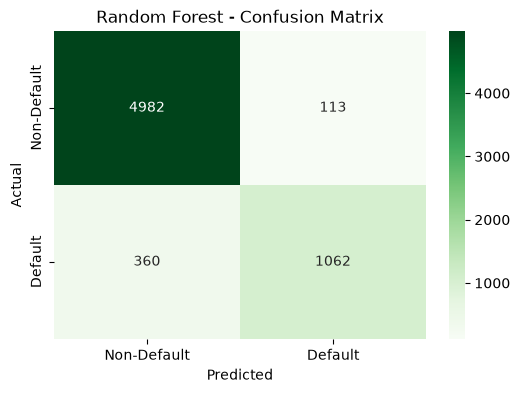

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Non-Default', 'Default'],
    yticklabels=['Non-Default', 'Default']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

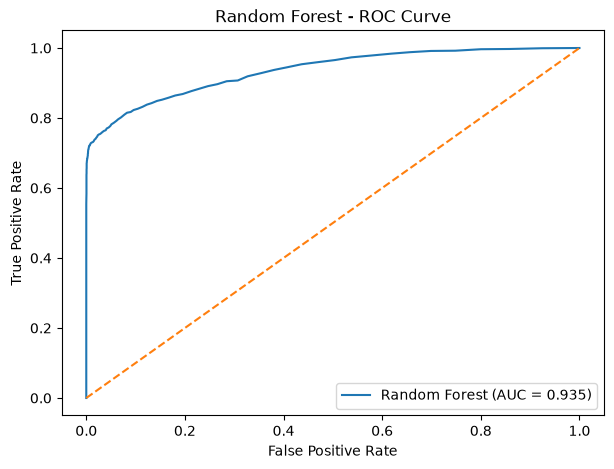

ROC-AUC Score: 0.9347832808150071


In [49]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prediction probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# AUC Score
auc_score = roc_auc_score(y_test, y_prob_rf)

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.show()

print("ROC-AUC Score:", auc_score)

In [50]:
import joblib

joblib.dump(rf_model, "../5-src/random_forest_model.pkl")

print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!
